# UMAP examples (Fig. 1B)

Draws the UMAP embedding of one representative starling and one representative zebra finch, coloured by syllable group, lighter for heliox and darker for regular air.

Reads one file, `umap_examples_data.pkl`, written by Cell U1 of the data notebook.

The schematic in Fig. 1A, and the lettering and arrows around the panels, were added in the layout program and are not drawn here.

In [1]:
# Cell 1: paths and figure style
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import hsv_to_rgb, to_rgb
from matplotlib.patches import Rectangle

# Paths relative to the repository, so a fresh clone runs without edits (from the repo folder or
# from notebooks/). To use other copies, e.g. on the cluster: export HELIOX_DATA_DIR=/path/to/data/derived
REPO = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
DATA_DIR = os.environ.get('HELIOX_DATA_DIR', os.path.join(REPO, 'data'))
FIG_DIR = os.environ.get('HELIOX_FIG_DIR', os.path.join(REPO, 'figures'))
DATA_PATH = os.path.join(DATA_DIR, 'umap_examples_data.pkl')
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({'font.size': 15, 'axes.titlesize': 19, 'axes.labelsize': 16, 'xtick.labelsize': 14,
                     'ytick.labelsize': 14, 'legend.fontsize': 13, 'savefig.dpi': 300, 'savefig.bbox': 'tight'})


def save(fig, name):
    for ext in ('png', 'pdf'):
        fig.savefig(os.path.join(FIG_DIR, f'{name}.{ext}'))
    print('saved', os.path.join(FIG_DIR, name + '.png'))

In [2]:
# Cell 2: load
data = pd.read_pickle(DATA_PATH)
syllables = data['syllables']
print('made', data['meta']['created'])
print(syllables.groupby(['species', 'bird', 'condition']).size().unstack().to_string())

made 2026-10-11T12:11:07
condition                heliox  regair
species     bird                       
starling    s_b1349h_23    8232    4451
zebra_finch z_r11g11_24    2232    4041


saved /mnt/cube/lstanwic/umap_avgn_shared/lauren_umap/heliox_processing/notebooks/for_github/figures/fig1B_umap_examples.png


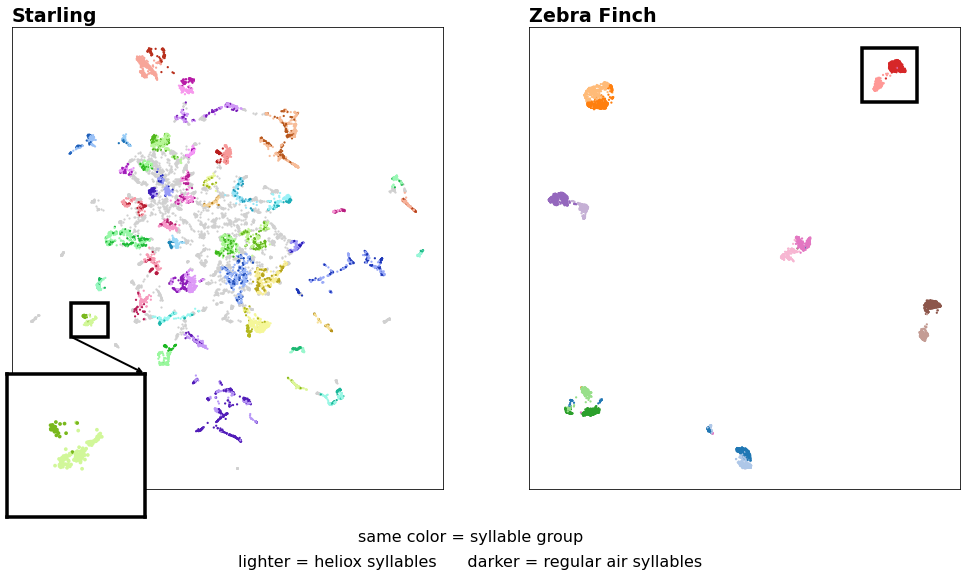

In [3]:
# Cell 3: Fig. 1B
SPECIES = [('starling', 'Starling'), ('zebra_finch', 'Zebra Finch')]
# Syllable group to frame in each panel. None = the group whose regular air and heliox syllables
# sit furthest apart. To frame a particular group, put its label here (labels are printed below).
BOX = {'starling': None, 'zebra_finch': None}
ZOOM = {'starling': True, 'zebra_finch': False}      # also draw the framed group enlarged
UNCLUSTERED = '#d0d0d0'


def group_colors(labels):
    """{label: (regular air colour, heliox colour)}: one hue per syllable group, the lighter shade for
    heliox. Up to nine groups use the dark/light pairs of tab20 (all but its grey pair, which would read
    as unclustered); more than that get hues spread around the colour wheel, in shuffled order so that
    consecutive labels do not look alike."""
    if len(labels) <= 9:
        tab = [c for i, c in enumerate(plt.get_cmap('tab20').colors) if i not in (14, 15)]
        return {lab: (tab[2 * i], tab[2 * i + 1]) for i, lab in enumerate(labels)}
    hues = np.random.default_rng(0).permutation(len(labels)) / len(labels)
    return {lab: (tuple(hsv_to_rgb((h, 0.85, 0.72))), tuple(hsv_to_rgb((h, 0.38, 0.97)))) for lab, h in zip(labels, hues)}


def most_separated(d, min_n=30):
    """Label of the group whose two conditions are furthest apart, in units of the group's own spread."""
    best, best_score = None, -np.inf
    for lab, g in d[d['clustered']].groupby('label'):
        a = g.loc[g['condition'] == 'regair', ['umap_x', 'umap_y']].to_numpy()
        b = g.loc[g['condition'] == 'heliox', ['umap_x', 'umap_y']].to_numpy()
        if min(len(a), len(b)) < min_n:
            continue
        score = np.linalg.norm(a.mean(axis=0) - b.mean(axis=0)) / np.sqrt((a.var(axis=0).sum() + b.var(axis=0).sum()) / 2)
        if score > best_score:
            best, best_score = lab, score
    return best


def scatter(ax, d, colors, size):
    loose, grouped = d[~d['clustered']], d[d['clustered']]
    ax.scatter(loose['umap_x'], loose['umap_y'], s=size, color=UNCLUSTERED, linewidths=0)
    rgb = np.array([colors[lab][int(cond == 'heliox')] for lab, cond in zip(grouped['label'], grouped['condition'])])
    order = np.random.default_rng(0).permutation(len(grouped))      # so neither condition is drawn on top
    ax.scatter(grouped['umap_x'].to_numpy()[order], grouped['umap_y'].to_numpy()[order], s=size, c=rgb[order], linewidths=0)
    ax.set_xticks([])
    ax.set_yticks([])


boxed = {}
fig, axes = plt.subplots(1, 2, figsize=(17, 8.5))
for ax, (species, title) in zip(axes, SPECIES):
    d = syllables[syllables['species'] == species]
    colors = group_colors(sorted(d.loc[d['clustered'], 'label'].unique()))
    scatter(ax, d, colors, size=5)
    ax.set_title(title, fontsize=19, fontweight='bold', loc='left')

    boxed[species] = BOX[species] if BOX[species] is not None else most_separated(d)
    g = d[d['clustered'] & (d['label'] == boxed[species])]
    if g.empty:
        continue
    pad = 0.03 * (d['umap_x'].max() - d['umap_x'].min())
    x0, x1, y0, y1 = g['umap_x'].min() - pad, g['umap_x'].max() + pad, g['umap_y'].min() - pad, g['umap_y'].max() + pad
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor='black', linewidth=3.5))
    if ZOOM[species]:
        inset = ax.inset_axes([-0.01, -0.06, 0.32, 0.31])            # lower left corner, as published
        scatter(inset, d[d['umap_x'].between(x0, x1) & d['umap_y'].between(y0, y1)], colors, size=14)
        inset.set_xlim(x0, x1)
        inset.set_ylim(y0, y1)
        for side in inset.spines.values():
            side.set_linewidth(3.5)
        ax.annotate('', xy=(0.31, 0.25), xycoords='axes fraction', xytext=(x0, y0), textcoords='data',
                    arrowprops=dict(arrowstyle='->', linewidth=2, color='black'))

fig.text(0.5, 0.04, 'same color = syllable group', ha='center', fontsize=16)
fig.text(0.5, 0.0, 'lighter = heliox syllables      darker = regular air syllables', ha='center', fontsize=16)
save(fig, 'fig1B_umap_examples')
plt.show()

In [4]:
# Cell 5 (example): run a new UMAP on the same syllables
# Fig. 1B above draws the embedding stored with the data. This shows how such an embedding is made.
# A new run will not look exactly like Fig. 1B: UMAP places clusters differently from run to run and
# from version to version. What stays the same is which syllables end up together.
import umap

SPECTROGRAMS_PATH = os.path.join(DATA_DIR, 'umap_example_spectrograms.pkl')
# the settings given in the Methods; a small n_neighbors keeps the many starling syllable types apart
UMAP_SETTINGS = {'starling': dict(n_neighbors=15, min_dist=0.2, metric='euclidean'),
                 'zebra_finch': dict(n_neighbors=300, min_dist=0.3, metric='euclidean')}
SEED = 42                      # the same layout every time on one machine; change it to see another

inputs = pd.read_pickle(SPECTROGRAMS_PATH)
frames = []
for species, title in SPECIES:
    d = inputs[species]
    # UMAP takes one row per syllable, so each spectrogram (frequency x time) is unrolled into one long row
    flat = d['spectrograms'].reshape(len(d['spectrograms']), -1)
    xy = umap.UMAP(random_state=SEED, **UMAP_SETTINGS[species]).fit_transform(flat)
    # stored_label: the syllable group each syllable has in the paper (starling: -1 = unclustered)
    frames.append(pd.DataFrame({'species': species, 'bird': d['bird'], 'condition': d['condition'],
                                'stored_label': d['label'], 'umap_x': xy[:, 0], 'umap_y': xy[:, 1]}))
    print(f'{title} ({d["bird"]}): {len(xy)} syllables, {flat.shape[1]} values each -> 2 UMAP dimensions')
new_umap = pd.concat(frames, ignore_index=True)

/home/AD/lstanwic/anaconda3/lib/python3.8/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


Starling (s_b1349h_23): 12683 syllables, 864 values each -> 2 UMAP dimensions


/home/AD/lstanwic/anaconda3/lib/python3.8/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


Zebra Finch (z_r11g11_24): 6273 syllables, 1408 values each -> 2 UMAP dimensions


In [5]:
# Cell 6 (example): group the starling syllables with HDBSCAN
# A starling sings many syllable types, and how many is not known in advance. HDBSCAN finds the groups
# itself: it looks for places in the UMAP embedding where syllables are packed closely together and
# calls each such place a cluster. It is never told how many clusters to find.
import hdbscan
from sklearn.metrics import adjusted_rand_score

# The one setting that matters: the smallest group that counts as a syllable type, as a fraction of
# the bird's syllables. 0.5% is the value used in the paper; Supp. Fig. S1 shows how it was chosen.
MIN_CLUSTER_FRACTION = 0.005

starling = new_umap['species'] == 'starling'
# z: one row per syllable, its two UMAP coordinates. HDBSCAN is run on these, not on the spectrograms.
z = new_umap.loc[starling, ['umap_x', 'umap_y']].to_numpy()

# with 12,000 syllables, 0.5% means a group needs at least 60 syllables to be a cluster
min_cluster_size = int(len(z) * MIN_CLUSTER_FRACTION)
clusterer = hdbscan.HDBSCAN(min_cluster_size=min_cluster_size).fit(z)

# One label per syllable: 0, 1, 2, ... name the clusters. -1 means HDBSCAN put the syllable in no
# cluster, because it sits in a sparse part of the embedding ("noise"). Those are the unclustered
# syllables, drawn in grey below and left out of the cluster-based analyses.
hdbscan_labels = clusterer.labels_
n_clusters = len(np.unique(hdbscan_labels[hdbscan_labels >= 0]))        # the -1 label is not a cluster
sizes = pd.Series(hdbscan_labels[hdbscan_labels >= 0]).value_counts()

print(f'number of syllables: {len(z)}')
print(f'minimum cluster size: {min_cluster_size}')
print(f'number of clusters: {n_clusters}')
print(f'unclustered syllables: {100 * (hdbscan_labels < 0).mean():.1f}%')
print(f'cluster sizes: {sizes.min()} to {sizes.max()} syllables (median {int(sizes.median())})')

# Does this run group the syllables the way the labels stored with the data do? The cluster numbers
# themselves mean nothing (cluster 3 here need not be cluster 3 there), so compare who is grouped with
# whom: the adjusted Rand index is 1 for identical groupings and about 0 for unrelated ones.
stored = new_umap.loc[starling, 'stored_label'].to_numpy().astype(int)
in_both = (hdbscan_labels >= 0) & (stored >= 0)
print(f'agreement with the stored labels ({len(np.unique(stored[stored >= 0]))} clusters): adjusted Rand index '
      f'{adjusted_rand_score(stored[in_both], hdbscan_labels[in_both]):.2f} over the {in_both.sum()} syllables '
      'clustered in both')

# Keep the result next to the embedding. Zebra finch syllable types were not found with HDBSCAN
# (k-means on the embedding, then labelled by hand), so those keep the labels stored with the data.
new_umap['label'] = new_umap['stored_label']
new_umap['clustered'] = True
new_umap.loc[starling, 'label'] = hdbscan_labels
new_umap.loc[starling, 'clustered'] = hdbscan_labels >= 0

number of syllables: 12683
minimum cluster size: 63
number of clusters: 46
unclustered syllables: 26.1%
cluster sizes: 66 to 742 syllables (median 161)
agreement with the stored labels (47 clusters): adjusted Rand index 0.87 over the 8278 syllables clustered in both


saved /mnt/cube/lstanwic/umap_avgn_shared/lauren_umap/heliox_processing/notebooks/for_github/figures/example_new_umap.png


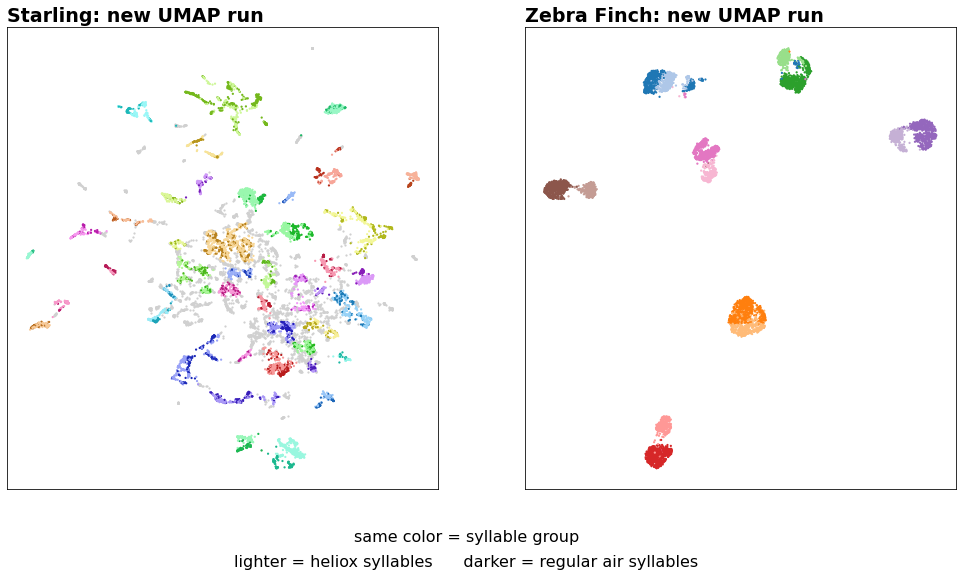

In [6]:
# Cell 7 (example): draw the new embedding, coloured as in Fig. 1B
# Starling: one colour per HDBSCAN cluster from Cell 6, grey = unclustered. Zebra finch: one colour per
# stored syllable type.
fig, axes = plt.subplots(1, 2, figsize=(17, 8.5))
for ax, (species, title) in zip(axes, SPECIES):
    d = new_umap[new_umap['species'] == species]
    scatter(ax, d, group_colors(sorted(d.loc[d['clustered'], 'label'].unique())), size=5)
    ax.set_title(f'{title}: new UMAP run', fontsize=19, fontweight='bold', loc='left')
fig.text(0.5, 0.04, 'same color = syllable group', ha='center', fontsize=16)
fig.text(0.5, 0.0, 'lighter = heliox syllables      darker = regular air syllables', ha='center', fontsize=16)
save(fig, 'example_new_umap')
plt.show()